# 04 · Semantic scoring, recommendation and explanations (P4)

**GenderBook NLP project, ECE ING5 Data & AI.** This notebook walks, step by step, through how the system goes from the questionnaire answers to an **explained top 3 of books**. It is also the basis of the "Scoring & recommendation" section of the report.

Modules used (all in `src/`):

| Module | Role |
|---|---|
| `schemas.py` | `UserProfile` and `Recommendation` dataclasses (contract with P5's app) |
| `profile.py` | `build_profile(answers, engine)`: answers → semantic profile |
| `scoring.py` | the scoring formula, computed in a vectorised way |
| `recommender.py` | `recommend(answers, top_k=3)`: single entry point of the app |
| `explain.py` | template-based explanations, no LLM |
| `fallback_engine.py` | fallback embedding engine as long as `embeddings.py` (P3) is not delivered |

**Pipeline:**
```
answers.json ─► build_profile ─► (1) hard filters ─► (2) top-300 retrieval by S_desc
             ─► (3) re-ranking with the formula ─► (4) diversity ─► (5) top 3 + explanations
```

**Formula** (detailed in section 6):

$$\text{Final}(j) = \frac{\alpha\,\tilde S_{desc}(j) + \beta\,\text{Coverage}(j) + \lambda\,\text{Pop}(j)}{\alpha+\beta+\lambda} \;-\; \mu \max\big(0,\ \cos(q_{avoid}, e_j) - \tau\big)$$

$$\text{Coverage}(j) = \frac{\sum_b W_b\,\tilde S_b(j)}{\sum_b W_b}, \qquad S_b(j) = \frac{1}{|P_b|}\sum_{p\in P_b}\ \max_{l \in L_b(j)\cup\{e_j\}} \cos(p, l)$$

## 1. Setup

We move to the repo root to be able to import `src/`. The SBERT model (`all-MiniLM-L6-v2`) is downloaded on the first run (≈ 90 MB), then encoding the 12,000 blurbs takes a few minutes on CPU. It is then **cached** in `data/embeddings/`: the following runs are instantaneous.

> Offline mode (tests only): `GENDERBOOK_ENCODER=lsa` replaces SBERT with TF-IDF + SVD. The results are then worse: do not use it for the report.

In [1]:
# Step 1: make the src/ folder importable from notebooks/
import sys, os, json, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.data_loader import load_books
from src.recommender import Recommender, load_blocks_safe
from src.profile import build_profile, likert_to_sentence, LIKERT_SENTENCES
from src.scoring import score_books, load_personas, calibrate, book_label_mask, desc_similarity
from src.explain import explain_score_formula
from src.schemas import BLOCKS

pd.set_option("display.max_colwidth", 120)
print("Encodeur :", os.environ.get("GENDERBOOK_ENCODER", "sbert"), "| modèle :", config.EMBEDDING_MODEL)

Encodeur : sbert | modèle : sentence-transformers/all-MiniLM-L6-v2


In [2]:
# Step 2: load the catalogue (enriched by P2 if it exists, otherwise P1's clean file or sample)
books = load_books()
blocks = load_blocks_safe()
print(f"{len(books)} livres | colonnes P2 présentes : {all(c in books for c in ['genres','themes','styles','atmospheres'])}")
print({b: len(v) for b, v in blocks.items()}, "labels par bloc")
books[["title", "main_author", "audience", "genres", "themes", "styles", "atmospheres", "popularity"]].head(3)

12000 livres | colonnes P2 présentes : True
{'Genre': 21, 'Themes': 20, 'Style': 10, 'Atmosphere': 15} labels par bloc


,title,main_author,audience,genres,themes,styles,atmospheres,popularity
0,Harry Potter and the Sorcerer's Stone,J.K. Rowling,Children,"[Fantasy, Humour, Children's]",[Friendship],[Simple & accessible],[Whimsical & magical],0.896000
1,The Hunger Games,Suzanne Collins,Young Adult,"[Young Adult, Historical Fiction]","[Grief & loss, Survival, Coming of age]",[Humorous & witty],[Melancholic],0.857940
2,"Twilight : Twilight, Book 1",Stephenie Meyer,Young Adult,"[Literary Fiction, Fantasy, Young Adult]",[Adventure & exploration],"[Plot-driven & twisty, Fast-paced page-turner]",[Dark & unsettling],0.705516


In [3]:
# Step 3: build the engine (catalogue + embeddings + label sentences + calibration)
# The first call encodes the 12,000 blurbs (disk cache afterwards).
t0 = time.time()
reco = Recommender(books=books, blocks=blocks)
print(f"Moteur prêt en {time.time() - t0:.1f} s | moteur : {type(reco.engine).__name__} "
      f"| matrice des livres : {reco.book_emb.shape}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Moteur prêt en 22.7 s | moteur : EmbeddingEngine | matrice des livres : (12000, 384)


## 2. An example user

We use a persona from `data/reference/personas_p4.json` (exact `answers.json` format, contract §4.3). It combines the **5 types of questions** required: free text, checkboxes, multiple choice, Likert and guided questions.

In [4]:
personas = load_personas()
answers = personas["dark_academia"]
print(json.dumps(answers, indent=2, ensure_ascii=False))

{
  "free_text": {
    "ideal_book": "I enjoy psychological novels exploring identity and moral dilemmas, with complex characters who hide dark secrets.",
    "loved_book": "I loved The Secret History because of the dark academic atmosphere and the group of students drawn into a crime.",
    "atmosphere": "Something melancholic, rainy, set in an old university",
    "avoid": "No romance-centered plots, no gore"
  },
  "genres": [
    "Literary Fiction",
    "Thriller & Suspense"
  ],
  "themes": [
    "Identity & self-discovery",
    "Morality & guilt",
    "Friendship"
  ],
  "period": "Contemporary",
  "audience": "Adult",
  "formats": [],
  "favorite_author": "Donna Tartt",
  "guided": {
    "focus": "Characters",
    "standalone_only": false,
    "exclude_favorite_author": true
  },
  "likert": {
    "complexity": 4,
    "pace": 2,
    "darkness": 4,
    "popularity": 3,
    "w_genre": 4,
    "w_themes": 5,
    "w_style": 3,
    "w_atmosphere": 4
  }
}


## 3. Step 1: the semantic profile (`build_profile`)

### 3.1 Likerts become sentences

This is the key point to meet the "*not purely numerical*" requirement. A rating from 1 to 5 means nothing to a language model: we **convert it into a sentence**, which is encoded and then compared with the books like any other text. Level 3 (neutral) produces no sentence: it means "no preference" and must not dilute the block.

In [5]:
# Likert -> sentence conversion table (used for the Style and Atmosphere blocks)
rows = []
for key, levels in LIKERT_SENTENCES.items():
    for v in range(1, 6):
        rows.append({"likert": key, "valeur": v, "phrase encodée": likert_to_sentence(key, v) or "(neutre : aucune phrase)"})
pd.DataFrame(rows)

,likert,valeur,phrase encodée
0,complexity,1,"a simple, easy and accessible story with clear, straightforward writing"
1,complexity,2,"an easy-to-read, light narrative that is not too demanding"
2,complexity,3,(neutre : aucune phrase)
3,complexity,4,a rich and layered narrative with some depth and complexity
4,complexity,5,"a complex, dense, literary and demanding narrative with sophisticated prose"
5,pace,1,"a slow, contemplative and quiet story that takes its time"
6,pace,2,"a gently paced, reflective story"
7,pace,3,(neutre : aucune phrase)
8,pace,4,a well-paced story with momentum and suspense
9,pace,5,"a fast-paced, gripping page-turner that is hard to put down"


### 3.2 Preference sentences per block $P_b(u)$

For each block, we gather the sentences describing what the user wants:

- **Genre**: the descriptive sentence (`blocks.json`) of each ticked genre;
- **Themes**: the sentences of the ticked themes + the free-text answer "a book you loved and why";
- **Style**: the complexity and pace Likerts converted into sentences + the *character / plot-driven* guided question;
- **Atmosphere**: the chosen period (P2 label) + the tone Likert as a sentence + the free-text answer about the mood.

We encode the **sentence** of a label, not the bare word: "boy wizard school" thus gets close to *Fantasy* without the word appearing.

In [6]:
profile = build_profile(answers, reco.engine, reco.books, reco.blocks)
for b in BLOCKS:
    print(f"\n{b}  (poids W = {profile.weights[b]:.0f})")
    for p in profile.block_phrases[b]:
        print("   •", p)
print("\nλ (bonus popularité) =", profile.lambda_pop)
print("Texte à éviter, négations retirées :", repr(profile.query_texts["avoid"]))
print("Auteur préféré retrouvé dans le catalogue :", profile.favorite_author)


Genre  (poids W = 4)
   • Literary fiction, a character-focused novel with artistic prose, psychological depth and insight into society
   • Gripping thriller and suspense novel with danger, conspiracies, spies, chases and high-stakes tension

Themes  (poids W = 5)
   • A story about self-discovery, identity and finding out who you really are
   • A story about moral dilemmas, right and wrong, guilt, conscience and consequences of choices
   • A story about friendship, loyalty, companionship and the people who stand by us
   • I loved The Secret History because of the dark academic atmosphere and the group of students drawn into a crime.

Style  (poids W = 3)
   • a rich and layered narrative with some depth and complexity
   • a gently paced, reflective story
   • a character-driven story with deep psychological portraits and inner lives

Atmosphere  (poids W = 4)
   • Set in the modern world today, with contemporary life, smartphones and current social issues
   • a serious, somber 

**Why remove the negations from the "to avoid" text?** SBERT encodes negation poorly: "*No romance*" is almost as close to romances as "*romance*". Rather than fighting this bias, we use it: we keep the **subject** to avoid ("romance-centered plots, gore") and penalise the books close to it.

### 3.3 Profile summary and affinities (app radar)

`block_affinities[b][label]` = maximum similarity between the user's preferences and the sentence of each label. P5 uses it for the "reader profile" radar.

In [7]:
print(profile.summary, "\n")
for b in BLOCKS:
    top = sorted(profile.block_affinities[b].items(), key=lambda kv: -kv[1])[:5]
    print(f"{b:<11}", " | ".join(f"{l} {s:.2f}" for l, s in top))

You are looking for Literary Fiction, Thriller & Suspense books exploring identity & self-discovery, morality & guilt, friendship. Your ideal style looks like: character-driven. Preferred atmosphere: contemporary and melancholic. What matters most to you: themes. Favourite author: Donna Tartt. Audience: Adult. 

Genre       Thriller & Suspense 1.00 | Literary Fiction 1.00 | Young Adult 0.55 | Historical Fiction 0.55 | Mystery & Detective 0.54
Themes      Friendship 0.89 | Morality & guilt 0.88 | Identity & self-discovery 0.84 | Redemption 0.60 | Family relationships 0.57
Style       Character-driven 0.95 | Dense literary prose 0.75 | Slow and contemplative 0.74 | Dark & gritty voice 0.58 | Fast-paced page-turner 0.56
Atmosphere  Contemporary 1.00 | Melancholic 0.64 | Dark & unsettling 0.62 | Future 0.55 | Romantic 0.47


### 3.4 Global query: concatenation or average?

`q_global` combines the 3 free-text answers. Two options:

- **concatenation**: a single text, the model sees the whole context, but a long answer crushes the others and MiniLM truncates beyond 256 tokens;
- **average** of the embeddings of each answer: each answer weighs the same and none is truncated.

We compare both on the personas: overlap of the first 10 retrieved books and cosine between the two vectors.

In [8]:
rows = []
for name, a in personas.items():
    p_mean = build_profile(a, reco.engine, reco.books, reco.blocks, how="mean")
    p_cat = build_profile(a, reco.engine, reco.books, reco.blocks, how="concat")
    top_m = set(np.argsort(-(reco.book_emb @ p_mean.query_vecs["global"]))[:10])
    top_c = set(np.argsort(-(reco.book_emb @ p_cat.query_vecs["global"]))[:10])
    rows.append({"persona": name,
                 "cos(q_mean, q_concat)": float(p_mean.query_vecs["global"] @ p_cat.query_vecs["global"]),
                 "top-10 communs": len(top_m & top_c)})
pd.DataFrame(rows).round(3)

,persona,"cos(q_mean, q_concat)",top-10 communs
0,dark_academia,0.951,5
1,young_fantasy,0.927,7
2,nordic_noir,0.938,6
3,philosophy_essay,0.893,8
4,historical_romance,0.945,6
5,dystopian_scifi,0.890,7
6,cozy_feelgood,0.950,8
7,true_life_memoir,0.861,4


**Reading.** The two vectors are close (cosine between 0.86 and 0.95), but not identical: depending on the persona, only 4 to 8 of the first 10 books are shared. The choice therefore has a real effect. The gap is largest for the personas with one answer much longer than the others (*true_life_memoir*: 4/10). This is exactly the case where concatenation lets the longest answer dominate. We keep the **average** (`config.QUERY_COMBINATION = "mean"`): each open question weighs the same, and none is truncated at 256 tokens. If the favourite author is found in the catalogue, we mix: $q_{global} = 0.7\,q_{text} + 0.3\,\bar e_{author}$ (centroid of their books), then renormalise.

## 4. Step 2: hard filters and retrieval

The **hard filters** (P1's `data_loader.apply_constraints`) remove the books outside the audience, outside the format or by the excluded author. Then the **retrieval** keeps the 300 books whose blurb is closest to $q_{global}$ (one matrix-vector product over 12,000 books, a few milliseconds). The more costly re-ranking only covers these candidates.

If no book passes the filters, they are relaxed in this order: formats, publication period, fiction, audience. Excluded authors are never relaxed.

Livres qui passent les filtres : 6912 / 12000  | filtres relâchés : []


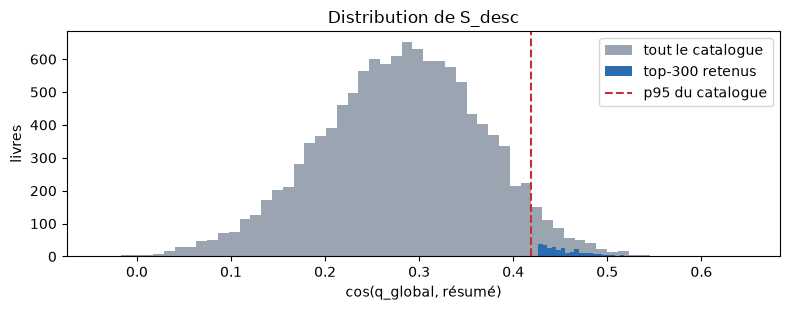

Part des candidats au-dessus du p95 du catalogue : 100%


In [9]:
mask = reco.filter_mask(profile, min_books=1)
print(f"Livres qui passent les filtres : {mask.sum()} / {len(mask)}  | filtres relâchés : {profile.constraints['relaxed']}")

sims_all = desc_similarity(profile.query_vecs["global"], reco.book_emb)
allowed = np.flatnonzero(mask)
cand = allowed[np.argsort(-sims_all[allowed])[:config.RETRIEVAL_TOP_K]]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(sims_all, bins=60, color="#9aa5b1", label="tout le catalogue")
ax.hist(sims_all[cand], bins=30, color="#2b6cb0", label=f"top-{config.RETRIEVAL_TOP_K} retenus")
ax.axvline(np.percentile(sims_all, 95), color="#c53030", ls="--", label="p95 du catalogue")
ax.set_xlabel("cos(q_global, résumé)"); ax.set_ylabel("livres"); ax.legend(); ax.set_title("Distribution de S_desc")
plt.tight_layout(); plt.show()
print(f"Part des candidats au-dessus du p95 du catalogue : {(sims_all[cand] > np.percentile(sims_all, 95)).mean():.0%}")

## 5. Step 3: calibration

SBERT cosines are **compressed** (often between 0.1 and 0.7): 0.45 can be an excellent score. To make them readable and comparable across components, we map them onto [0, 1]:

$$\tilde s = \text{clip}\left(\frac{s - p_5}{p_{95} - p_5},\ 0,\ 1\right)$$

**Important choice.** The plot above shows that the 300 candidates are *all* above the catalogue's p95 (the retrieval keeps the top 2.5%). Calibrating on the whole catalogue would therefore give $\tilde S_{desc} = 1$ to all candidates and this term would no longer separate anything. We therefore compute $p_5$ and $p_{95}$ **over the candidates retrieved for 8 reference personas**. The calibration is then **fixed** (saved in `data/embeddings/calibration_p4.json`): a score of 0.8 has the same meaning for all users.

In [10]:
pd.DataFrame(reco.calibration, index=["p5", "p95"]).T.round(3)

,p5,p95
S_desc,0.373,0.547
Genre,0.296,1.000
Themes,0.347,0.675
Style,0.368,0.870
Atmosphere,0.247,0.627


## 6. Step 4: the computation by hand on 3 books

Like the assignment's "Step 1 to 5" example, we detail each term for 3 books of the top. We recompute the coverage and the final score **by hand** and check that we find the output of `score_books`.

Reminder of the constants (`src/config.py`): $\alpha = 0.5$ (blurb), $\beta = 0.4$ (coverage), $\lambda \in [0; 0.2]$ (popularity, set by the Likert), $\mu = 0.5$ and $\tau = 0.3$ ("to avoid" penalty).

In [11]:
table = reco.score_table(profile)
top3 = table.head(3)
cols = ["S_desc_raw", "S_desc"] + [c for b in BLOCKS for c in (f"{b}_raw", b)] + ["coverage", "popularity", "avoid_sim", "penalty", "final"]
show = top3[cols].copy()
show.insert(0, "title", reco.books.loc[top3.index, "title"].str[:40])
show.round(3)

,title,S_desc_raw,S_desc,Genre_raw,Genre,Themes_raw,Themes,Style_raw,Style,Atmosphere_raw,Atmosphere,coverage,popularity,avoid_sim,penalty,final
861,The Secret Keeper,0.571,1.000,1.000,1.000,0.486,0.422,0.487,0.237,0.313,0.175,0.470,0.619,0.210,0.0,0.750
6233,The Keep,0.564,1.000,0.772,0.677,0.561,0.651,0.536,0.336,0.343,0.252,0.499,0.416,0.295,0.0,0.741
3068,These Things Hidden : A Novel of Suspens,0.537,0.942,1.000,1.000,0.475,0.391,0.487,0.237,0.293,0.123,0.447,0.511,0.271,0.0,0.701


In [12]:
# Manual recomputation of the 1st book's score, term by term
row = top3.iloc[0]
W = profile.weights; lam = profile.lambda_pop
a, b_, mu, tau = config.ALPHA_DESC, config.BETA_COVERAGE, config.MU_AVOID, config.TAU_AVOID

print("Calibration de S_desc :", f"({row.S_desc_raw:.3f} - {reco.calibration['S_desc'][0]:.3f}) / "
      f"({reco.calibration['S_desc'][1]:.3f} - {reco.calibration['S_desc'][0]:.3f}) -> {row.S_desc:.3f}")
cov = sum(W[b] * row[b] for b in BLOCKS) / sum(W.values())
print("Coverage = (" + " + ".join(f"{W[b]:.0f}×{row[b]:.3f}" for b in BLOCKS) + f") / {sum(W.values()):.0f} = {cov:.3f}")
pen = mu * max(0.0, row.avoid_sim - tau)
final = (a * row.S_desc + b_ * cov + lam * row.popularity) / (a + b_ + lam) - pen
print(f"Final = ({a}×{row.S_desc:.3f} + {b_}×{cov:.3f} + {lam}×{row.popularity:.3f}) / {a + b_ + lam:.2f} - {pen:.3f} = {final:.3f}")
assert abs(cov - row.coverage) < 1e-5 and abs(min(max(final, 0), 1) - row.final) < 1e-5
print("✔ identique à score_books")

Calibration de S_desc : (0.571 - 0.373) / (0.547 - 0.373) -> 1.000
Coverage = (4×1.000 + 5×0.422 + 3×0.237 + 4×0.175) / 16 = 0.470
Final = (0.5×1.000 + 0.4×0.470 + 0.1×0.619) / 1.00 - 0.000 = 0.750
✔ identique à score_books


**Justification of each term:**

- **$\tilde S_{desc}$ (α = 0.5)**: the similarity between what the user writes and the book's blurb. It is the richest semantic signal (free text against free text), hence the highest weight.
- **Coverage (β = 0.4)**: the weighted average of the 4 blocks, required by the assignment. It checks that the book covers *each* requested dimension (genre, themes, style, atmosphere) and not just the general subject. The weights $W_b$ come directly from the importance Likerts: the user decides what matters.
- **"Max then mean" rule in $S_b$**: for each preference, we keep the book label that best answers it (max), then average over the preferences. A book must therefore answer *all* the preferences of the block to get a good score. The description $e_j$ is added to the candidates of the max: if P2 did not assign a label, the blurb can still answer.
- **λ·Pop (0 to 0.2)**: a small bonus for well-known, well-rated books, set by the "hidden gems ↔ best-sellers" Likert. It stays small so that it never dominates the semantics.
- **Division by α + β + λ**: guarantees Final ∈ [0, 1] whatever λ, so that the thresholds *Excellent ≥ 0.75 / Good ≥ 0.55 / Partial* mean the same for all users.
- **Penalty μ·max(0, cos − τ)**: only applies beyond τ = 0.3 (below that, the resemblance with the subject to avoid is noise), and μ = 0.5 makes it clearly visible.

## 7. Step 5: the final top 3, with its explanations

`recommend()` chains everything, applies the **diversity** rule (at most one book per author), then builds the `Recommendation` objects. The explanation is generated from a **template** using the real results: similarity, closest sentence of the blurb, shared labels, strongest and weakest criterion.

In [13]:
profile, recs = reco.recommend(answers, top_k=3)
for r in recs:
    print(f"#{r.rank}  {r.title} | {r.authors}  →  {r.final_score:.0%} ({r.match_label})")
    print("   Explanation :", r.explanation)
    print("   " + explain_score_formula(r, profile).replace("\n", "\n   "))
    print()

#1  The Secret Keeper | Kate Morton  →  75% (Excellent)
   Explanation : This book is an excellent match for what you described. Its synopsis is semantically close to your description (similarity 0.57), especially: «Shifting between the 1930s, the 1960s and the present, The Secret Keeper is a spellbinding story of mysteries and secrets, murder and enduring love.». Genre match: Thriller & Suspense (1.00), Literary Fiction (1.00). What weighs most in its score: how close its synopsis is to your description. It is a weaker match on the atmosphere (17%). Overall preference coverage: 47%. It is also a popular, well-rated book.
   S_desc (calibrated) = 1.00  (raw cosine 0.57)
   S_Genre = 1.00  (raw 1.00, weight W=4)
   S_Themes = 0.42  (raw 0.49, weight W=5)
   S_Style = 0.24  (raw 0.49, weight W=3)
   S_Atmosphere = 0.17  (raw 0.31, weight W=4)
   Coverage = Σ W·S / Σ W = 4×1.00 + 5×0.42 + 3×0.24 + 4×0.17 / 16 = 0.47
   Popularity = 0.62 (λ = 0.10)
   Avoid similarity = 0.21 → penalty 0.00

In [14]:
# Score breakdown (what P5 shows as stacked bars): the sum of the contributions = final score
pd.DataFrame({r.title[:35]: r.contributions for r in recs}).T.round(3)

,Description,Genre,Themes,Style,Atmosphere,Popularity,Avoid penalty
The Secret Keeper,0.500,0.100,0.053,0.018,0.018,0.062,-0.0
The Keep,0.500,0.068,0.081,0.025,0.025,0.042,-0.0
These Things Hidden : A Novel of Su,0.471,0.100,0.049,0.018,0.012,0.051,-0.0


**Reading the top 3 (*dark academia* persona).** The recommendations are literary fiction about secrets, crimes and guilt, consistent with the request.

**A case fixed after the PR review.** In the first version, the 3rd book was *My Secret: A PostSecret Book*, a **non-fiction** collection of anonymous postcards. Three causes added up:

1. **The word "secrets" in the description** ("*characters who hide dark secrets*") strongly pulled the similarity: this book had the highest raw cosine of the three (0.60). SBERT captures the shared *subject*, not the *nature* of the book (novel or testimony).
2. **A wrong P2 label**: the book carries the *Thriller & Suspense* genre.
3. **A category misclassified by P1**: "Humour Collections & Anthologies" is counted as fiction, hence `is_fiction = True`.

**Fix.** When the user ticks only fiction genres (`config.FICTION_GENRES`) and does not answer "fiction only", `profile.auto_fiction_only` enables the `fiction_only` filter. This filter also discards the books whose "fiction" categories are all collections (`config.NON_NARRATIVE_CATEGORY_RE`). This removes 5 books from the catalogue, including both *PostSecret* books.

We also notice that the best candidates often have $\tilde S_{desc} = 1$: the global similarity exceeds the calibration p95. The blurb term therefore no longer separates the top of the ranking, and it is the **coverage** and the **popularity** that order the top 3.

## 8. Three contrasting personas: is the system consistent?

We check that very different requests give very different and relevant recommendations: children's fantasy, dark Nordic noir, philosophical essay. We also measure a simple **genre precision**: the share of the top-3 books carrying at least one of the ticked genres.

In [15]:
def genre_precision(recs, wanted):
    g = reco.books.set_index("book_id").loc[[r.book_id for r in recs], "genres"]
    return float(np.mean([bool(set(x) & set(wanted)) for x in g])) if len(recs) else 0.0

rows = []
for name in ["young_fantasy", "nordic_noir", "philosophy_essay"]:
    p, rs = reco.recommend(personas[name], top_k=3)
    for r in rs:
        rows.append({"persona": name, "rang": r.rank, "titre": r.title[:45], "auteur": r.authors[:25],
                     "score": r.final_score, "label": r.match_label,
                     "genres du livre": ", ".join(reco.books.set_index("book_id").at[r.book_id, "genres"])})
    print(f"{name:<17} précision de genre@3 = {genre_precision(rs, personas[name]['genres']):.2f}")
pd.DataFrame(rows)

young_fantasy     précision de genre@3 = 1.00
nordic_noir       précision de genre@3 = 1.00
philosophy_essay  précision de genre@3 = 1.00


,persona,rang,titre,auteur,score,label,genres du livre
0,young_fantasy,1,"The Lion, the Witch and the Wardrobe",C. S. Lewis,0.8957,Excellent,"Fantasy, Literary Fiction, Young Adult"
1,young_fantasy,2,The Neverending Story,Michael Ende,0.8311,Excellent,"Fantasy, Classics, Young Adult"
2,young_fantasy,3,The Farthest Shore,Ursula K Le Guin,0.8030,Excellent,"Fantasy, Young Adult, Science Fiction"
3,nordic_noir,1,An Incomplete Revenge,Jacqueline Winspear,0.8948,Excellent,"Mystery & Detective, Thriller & Suspense"
4,nordic_noir,2,The Shining Girls,Lauren Beukes,0.8811,Excellent,"Thriller & Suspense, Mystery & Detective, Literary Fiction"
5,nordic_noir,3,The Girl Who Kicked the Hornets' Nest : The t,Stieg Larsson,0.8781,Excellent,"Mystery & Detective, Thriller & Suspense, Cooking & Lifestyle"
6,philosophy_essay,1,THE Power of Now,Eckhart Tolle,0.9518,Excellent,Philosophy & Religion
7,philosophy_essay,2,Status Anxiety,Alain de Botton,0.9284,Excellent,"Self-help & Psychology, Philosophy & Religion"
8,philosophy_essay,3,Awareness,Anthony de Mello,0.9088,Excellent,"Philosophy & Religion, Self-help & Psychology"


## 9. Sensitivity: do the user's settings have the expected effect?

Three quick checks:

1. **Theme weight**: we move $W_{Themes}$ from 1 to 5; the average Themes score of the top 10 should go up.
2. **Popularity**: we move the Likert from 1 (hidden gems) to 5 (best-sellers); the average popularity of the top 10 should go up.
3. **Text to avoid**: we add "no romance"; the books close to romance should be penalised.

In [16]:
import copy

def top10_mean(a, col):
    p = build_profile(a, reco.engine, reco.books, reco.blocks)
    t = reco.score_table(p).head(10)
    return float(t[col].mean())

base = copy.deepcopy(personas["dark_academia"]); base["free_text"]["avoid"] = ""
rows = []
for w in (1, 5):
    a = copy.deepcopy(base); a["likert"]["w_themes"] = w
    rows.append({"réglage": f"w_themes = {w}", "mesure": "S̃_Themes moyen (top 10)", "valeur": top10_mean(a, "Themes")})
for pop in (1, 5):
    a = copy.deepcopy(base); a["likert"]["popularity"] = pop
    rows.append({"réglage": f"popularity = {pop}", "mesure": "popularité moyenne (top 10)", "valeur": top10_mean(a, "popularity")})
for avoid in ("", "No romance, no love story"):
    a = copy.deepcopy(base); a["free_text"]["avoid"] = avoid
    p = build_profile(a, reco.engine, reco.books, reco.blocks)
    t = reco.score_table(p).head(10)
    is_rom = reco.books.loc[t.index, "genres"].map(lambda g: "Romance" in g)
    rows.append({"réglage": f"avoid = {avoid!r}", "mesure": "livres Romance dans le top 10", "valeur": int(is_rom.sum())})
pd.DataFrame(rows).round(3)

,réglage,mesure,valeur
0,w_themes = 1,S̃_Themes moyen (top 10),0.357
1,w_themes = 5,S̃_Themes moyen (top 10),0.373
2,popularity = 1,popularité moyenne (top 10),0.489
3,popularity = 5,popularité moyenne (top 10),0.499
4,avoid = '',livres Romance dans le top 10,2.000
5,"avoid = 'No romance, no love story'",livres Romance dans le top 10,2.000


**Reading.** The expected effects are weak, or even absent:

- **Theme weight**: moving $W_{Themes}$ from 1 to 5 raises the average Themes score of the top 10 from 0.357 to 0.373. The effect goes in the right direction but stays modest: since the automatic fiction filter, the candidates are already very close on themes, and the weight $W_{Themes}$ only reorders neighbouring books.
- **Popularity**: the Likert from 1 to 5 barely changes the average popularity of the top 10 (0.489 → 0.499). With $\lambda \le 0.2$, the bonus remains too weak to reorder the first 10 books of this persona. This is intended (popularity must not dominate the semantics), but the effect is almost invisible. P6 can test $\lambda_{max} = 0.4$ in the ablation.
- **Text to avoid**: adding "No romance" does not remove the 2 romance books from the top 10. With MiniLM, the similarity between "romance, love story" and the blurbs mostly stays below the threshold $\tau = 0.3$: the penalty almost never triggers. P6 can test $\tau = 0.2$.

These last two points are **measured limitations**, reported in the summary (section 12) and in the report.

## 10. Mini-ablation of the formula

P6 will do the full ablation. Here, a first check on the 8 personas: we compare the full formula with variants missing one term, using genre precision@3 and the overlap of the top 3 with the full formula.

In [17]:
variants = {
    "formule complète": {},
    "S_desc seul": {"alpha": 1.0, "beta": 0.0},
    "Coverage seule": {"alpha": 0.0, "beta": 1.0},
    "sans calibration": {"use_calibration": False},
    "sans pénalité avoid": {"mu": 0.0},
}
ref_top = {}
rows = []
for vname, kw in variants.items():
    precs, overlaps = [], []
    for name, a in personas.items():
        p, rs = reco.recommend(a, top_k=3, **kw)
        ids = [r.book_id for r in rs]
        if vname == "formule complète":
            ref_top[name] = set(ids)
        precs.append(genre_precision(rs, a["genres"]))
        overlaps.append(len(set(ids) & ref_top[name]) / 3)
    rows.append({"variante": vname, "précision de genre@3": np.mean(precs), "top 3 communs avec la formule complète": np.mean(overlaps)})
pd.DataFrame(rows).round(2)

,variante,précision de genre@3,top 3 communs avec la formule complète
0,formule complète,0.92,1.00
1,S_desc seul,0.75,0.33
2,Coverage seule,1.00,0.25
3,sans calibration,0.96,0.67
4,sans pénalité avoid,0.92,1.00


**Reading.**

- **S_desc alone** makes genre precision drop (0.75 against 0.92): without the blocks, free text alone brings back books close in subject but not in genre (like *PostSecret* before the fiction filter fix, section 7).
- **Coverage alone** reaches 1.00 in genre precision, but only keeps 25% of the full formula's top 3. This figure is flattering by construction: genre precision measures P2's labels, which coverage optimises directly. On the other hand, this variant ignores the nuance of the free text (the mood, the loved book).
- **S_desc alone** only keeps 33% of the full formula's top 3.
- **Without calibration**: 67% of the top 3 is kept, and precision rises slightly (0.96). Without calibration, the Genre block (cosine of 1 when the label is exact) weighs more.
- **Without the avoid penalty**: nothing changes (100% of the top 3 kept), which confirms that the penalty almost never triggers with $\tau = 0.3$ (see section 9).

**Conclusion**: combining free text and coverage (α = 0.5, β = 0.4) is a trade-off between faithfulness to the description and respect of the ticked genres. The figures cover 8 personas only: P6 will confirm with the full ablation.

## 11. Performance

In [18]:
t0 = time.time()
for a in personas.values():
    reco.recommend(a, top_k=3)
dt = (time.time() - t0) / len(personas)
print(f"Temps moyen d'une recommandation complète (profil + scoring + explications) : {dt * 1000:.0f} ms")

Temps moyen d'une recommandation complète (profil + scoring + explications) : 326 ms


## 12. Summary and limitations

**What the P4 part does:**
- turns *all* answers (including Likerts and guided choices) into sentences encoded by SBERT: the analysis stays semantic from end to end;
- computes an affinity score per block and a **coverage score** $\sum W_b S_b / \sum W_b$, as required by the assignment;
- recommends a diversified top 3, each book with its score, its label, its main criteria, the closest sentence of the blurb and a template-based explanation;
- computes everything in numpy (no loop over the books): a full recommendation takes about 0.3 s on CPU, most of which is spent encoding the answers and finding the closest sentence.

**Measured results (MiniLM, 12,000 books):** genre precision@3 of 1.00 on the 3 contrasting personas and of 0.92 on the 8 personas; the theme weight acts in the right direction, but weakly (0.357 → 0.373).

**Limitations:**
- **Subject proximity ≠ relevance**: a strong word of the request can pull up an off-topic book. Measured example: *My Secret: A PostSecret Book* (non-fiction) came out in the top 3 of the *dark academia* persona, because of the word "secrets". Fixed by the automatic fiction filter (section 7), but the risk remains for a user who ticks both fiction and non-fiction;
- **Dependence on P1 and P2 labels** (themes F1 ≈ 0.40 on the test set): *PostSecret* wrongly carries the *Thriller & Suspense* genre (P2) and is classified as fiction (P1). The description acts as a safety net, but a label error propagates to the score;
- **Explanations**: only the requested labels (ticked, inferred from the Likerts, or top 3 affinities) are cited, and never a label that contradicts an answer (no "Fast-paced page-turner" if a slow pace was requested);
- **Saturation of $\tilde S_{desc}$ at the top of the ranking**: the best candidates exceed the calibration p95, so the blurb term no longer separates the top 3;
- **Popularity and "to avoid" penalty barely active**: with $\lambda \le 0.2$ and $\tau = 0.3$, they hardly change the top 10 of the tested persona; to be tuned by P6's ablation;
- **Negation**: SBERT handles negation poorly; we remove negative words from the "to avoid" text, but a nuanced sentence ("not too much romance, a little is fine") is still poorly understood;
- **Calibration**: it depends on the 8 reference personas; more personas (P6) would make it more robust;
- **Series**: no series information in the dataset, so the "standalone only" preference is recorded but not filtered.